# Análisis ANOVA Oneway y Multifactorial - Base de Datos GAC

In [1]:
%pip install statsmodels pandas numpy matplotlib seaborn scipy

In [3]:
# Cargar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats
from statsmodels.graphics.factorplots import interaction_plot

In [4]:
# Cargar archivo CSV y preparar los datos
df = pd.read_csv('Analisis GAC Full7agosto 2026(Plazas).csv', low_memory=False)
df = df.bfill().ffill()
df.columns = df.columns.str.strip()

# Mapeo de variables booleanas a binarias (0 y 1)
for col in ['Seguimiento', 'Cita efetiva', 'PDM', 'SDC']:
    df[col] = df[col].astype(str).str.upper().map({'TRUE': 1, 'FALSE': 0}).fillna(0)

# Agrupación para generar las 3 variables objetivo cuantitativas
df_grouped = df.groupby(['Asesor', 'Origen', 'Producto'], as_index=False).agg({
    'Cita efetiva': 'mean',
    'PDM': 'mean',
    'SDC': 'mean'
}).rename(columns={
    'Cita efetiva': 'Cita_Efectiva_Rate',
    'PDM': 'PDM_Rate',
    'SDC': 'SDC_Rate'
})

df_grouped.head()

/tmp/ipykernel_1493/3896112004.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.bfill().ffill()


,Asesor,Origen,Producto,Cita_Efectiva_Rate,PDM_Rate,SDC_Rate
0,AURELIO FELIPE TORRES REVILLA,PLAZA ANGELOPOLIS,EMKOO,0.500000,0.000000,0.5
1,AURELIO FELIPE TORRES REVILLA,PLAZA ANGELOPOLIS,EMZOOM,0.000000,0.000000,0.0
2,AURELIO FELIPE TORRES REVILLA,PLAZA ANGELOPOLIS,GS8,1.000000,1.000000,0.5
3,Alan GonzÃ¡lez Belanzate,PLAZA ANGELOPOLIS,EMKOO,0.000000,0.000000,0.0
4,Alan GonzÃ¡lez Belanzate,PLAZA ANGELOPOLIS,EMZOOM,0.142857,0.142857,0.0


## 1. DIAGRAMAS DE CAJA (PANDAS BOXPLOT)

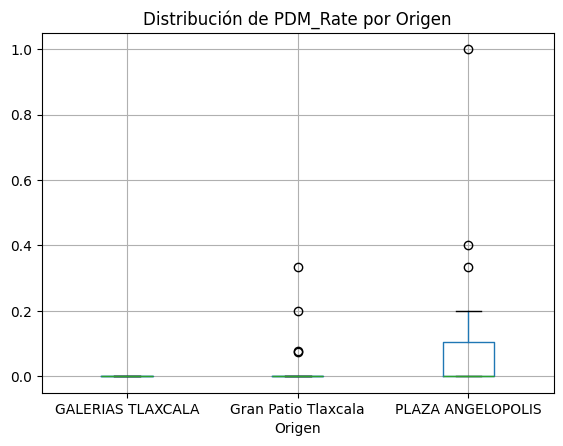

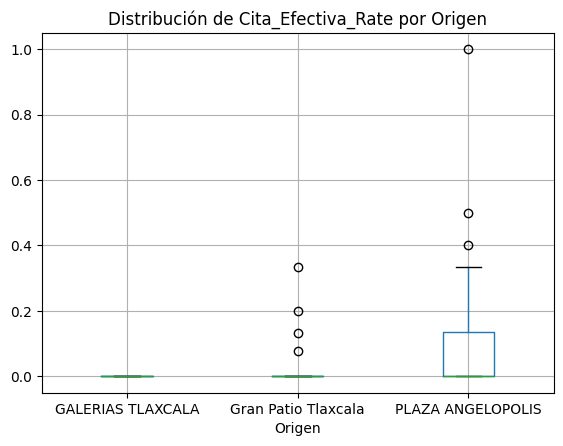

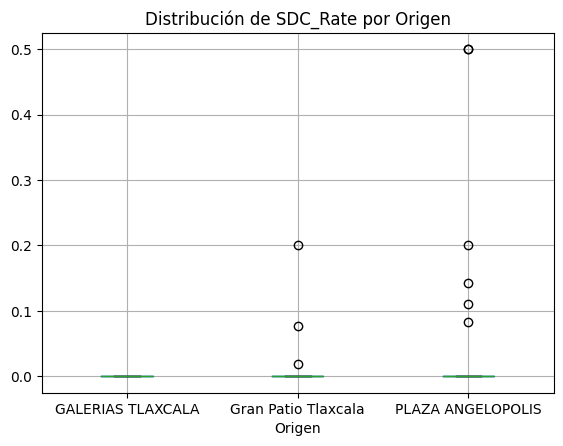

In [15]:
df_grouped.boxplot('PDM_Rate', by='Origen')
plt.title('Distribución de PDM_Rate por Origen')
plt.suptitle('')

df_grouped.boxplot('Cita_Efectiva_Rate', by='Origen')
plt.title('Distribución de Cita_Efectiva_Rate por Origen')
plt.suptitle('')

df_grouped.boxplot('SDC_Rate', by='Origen')
plt.title('Distribución de SDC_Rate por Origen')
plt.suptitle('')

plt.show()

## 2. GRÁFICO DE BARRAS CON BARRAS DE ERROR (IC AL 95%)
Muestra la media por categoría con intervalo de confianza del 95%.

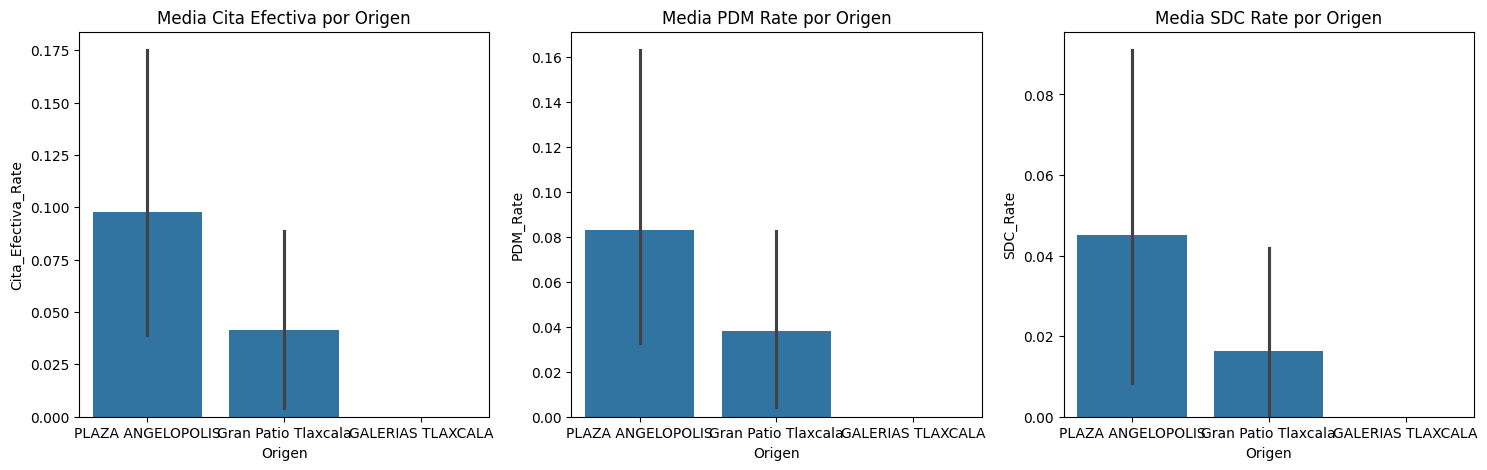

In [11]:
# Gráficos de barras con barras de error al 95% CI
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=df_grouped, x='Origen', y='Cita_Efectiva_Rate', ax=axes[0], errorbar=('ci', 95))
axes[0].set_title('Media Cita Efectiva por Origen')

sns.barplot(data=df_grouped, x='Origen', y='PDM_Rate', ax=axes[1], errorbar=('ci', 95))
axes[1].set_title('Media PDM Rate por Origen')

sns.barplot(data=df_grouped, x='Origen', y='SDC_Rate', ax=axes[2], errorbar=('ci', 95))
axes[2].set_title('Media SDC Rate por Origen')

plt.show()

## 3. GRÁFICO DE VIOLÍN (VIOLIN PLOT)
Visualización de la distribución mediante gráfico de violín.

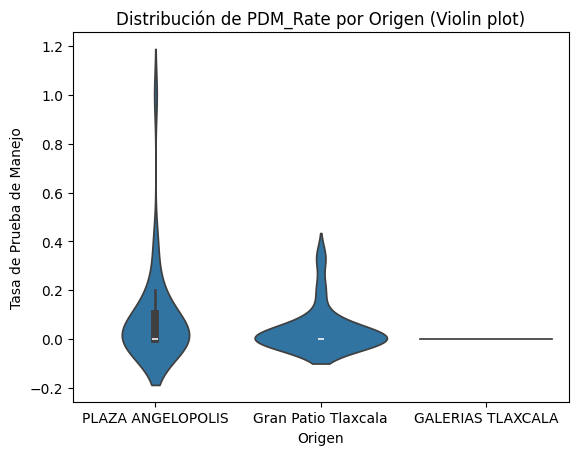

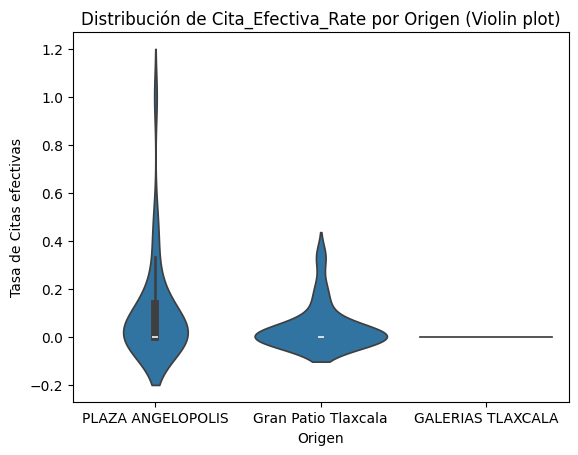

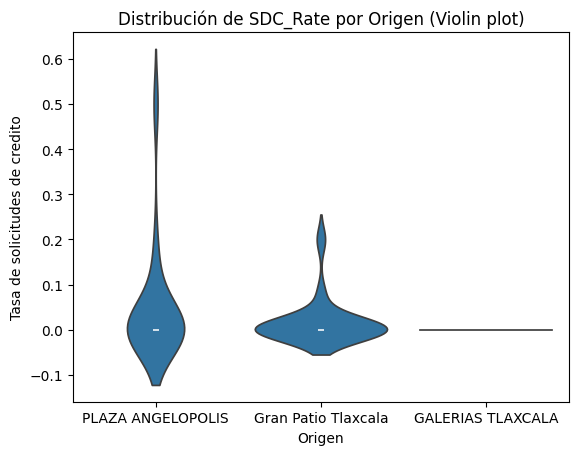

In [16]:
sns.violinplot(data=df_grouped, x='Origen', y='PDM_Rate', inner='box')
plt.title('Distribución de PDM_Rate por Origen (Violin plot)')
plt.ylabel('Tasa de Prueba de Manejo')
plt.xlabel('Origen')
plt.show()

sns.violinplot(data=df_grouped, x='Origen', y='Cita_Efectiva_Rate', inner='box')
plt.title('Distribución de Cita_Efectiva_Rate por Origen (Violin plot)')
plt.ylabel('Tasa de Citas efectivas')
plt.xlabel('Origen')
plt.show()

sns.violinplot(data=df_grouped, x='Origen', y='SDC_Rate', inner='box')
plt.title('Distribución de SDC_Rate por Origen (Violin plot)')
plt.ylabel('Tasa de solicitudes de credito')
plt.xlabel('Origen')
plt.show()

## 4. OBTENCIÓN DE CATEGORÍAS Y PREPARACIÓN DE GRUPOS (MÉTODO SCIPY)

In [24]:
# Obtengo las categorías de la variable (Origen)
grupos = pd.unique(df_grouped['Origen'].values)
print(grupos)

#p-value < 0.05, se rechaza la hipótesis de que todas las medias son iguales
#p-value < 0.05, implica que la variable categórica influye en la variable cuantitativa
# --- 1. GRUPOS Y ANOVA PARA PDM_Rate ---
PDM_1 = df_grouped.PDM_Rate[df_grouped.Origen == grupos[0]]
PDM_2 = df_grouped.PDM_Rate[df_grouped.Origen == grupos[1]]
PDM_3 = df_grouped.PDM_Rate[df_grouped.Origen == grupos[2]]

anova_pdm = stats.f_oneway(PDM_1, PDM_2, PDM_3)
print('Scipy ANOVA (PDM_Rate):', anova_pdm)


# --- 2. GRUPOS Y ANOVA PARA Cita_Efectiva_Rate ---
Cita_1 = df_grouped.Cita_Efectiva_Rate[df_grouped.Origen == grupos[0]]
Cita_2 = df_grouped.Cita_Efectiva_Rate[df_grouped.Origen == grupos[1]]
Cita_3 = df_grouped.Cita_Efectiva_Rate[df_grouped.Origen == grupos[2]]

anova_cita = stats.f_oneway(Cita_1, Cita_2, Cita_3)
print('Scipy ANOVA (Cita_Efectiva_Rate):', anova_cita)


# --- 3. GRUPOS Y ANOVA PARA SDC_Rate ---
SDC_1 = df_grouped.SDC_Rate[df_grouped.Origen == grupos[0]]
SDC_2 = df_grouped.SDC_Rate[df_grouped.Origen == grupos[1]]
SDC_3 = df_grouped.SDC_Rate[df_grouped.Origen == grupos[2]]

anova_sdc = stats.f_oneway(SDC_1, SDC_2, SDC_3)
print('Scipy ANOVA (SDC_Rate):', anova_sdc)

['PLAZA ANGELOPOLIS' 'Gran Patio Tlaxcala' 'GALERIAS TLAXCALA']
Scipy ANOVA (PDM_Rate): F_onewayResult(statistic=np.float64(0.618167567876398), pvalue=np.float64(0.5429197646456889))
Scipy ANOVA (Cita_Efectiva_Rate): F_onewayResult(statistic=np.float64(0.8340201872938886), pvalue=np.float64(0.4401360232555658))
Scipy ANOVA (SDC_Rate): F_onewayResult(statistic=np.float64(0.5613558463141789), pvalue=np.float64(0.5739194495704101))


## 5. STATSMODELS (ANOVA )

In [19]:
# ANOVA ONEWAY con Statsmodels para las 3 variables objetivo
print('ANOVA statsmodel: PDM_Rate')
mod_pdm = ols('PDM_Rate ~ Origen', data=df_grouped).fit()
print(sm.stats.anova_lm(mod_pdm, typ=1))

print('ANOVA statsmodel: Cita_Efectiva_Rate')
mod_cita = ols('Cita_Efectiva_Rate ~ Origen', data=df_grouped).fit()
print(sm.stats.anova_lm(mod_cita, typ=1))

print('ANOVA statsmodel: SDC_Rate')
mod_sdc = ols('SDC_Rate ~ Origen', data=df_grouped).fit()
print(sm.stats.anova_lm(mod_sdc, typ=1))

ANOVA statsmodel: PDM_Rate
            df    sum_sq   mean_sq         F   PR(>F)
Origen     2.0  0.032360  0.016180  0.618168  0.54292
Residual  51.0  1.334871  0.026174       NaN      NaN
ANOVA statsmodel: Cita_Efectiva_Rate
            df    sum_sq   mean_sq        F    PR(>F)
Origen     2.0  0.049122  0.024561  0.83402  0.440136
Residual  51.0  1.501886  0.029449      NaN       NaN
ANOVA statsmodel: SDC_Rate
            df    sum_sq   mean_sq         F    PR(>F)
Origen     2.0  0.012143  0.006071  0.561356  0.573919
Residual  51.0  0.551602  0.010816       NaN       NaN


## 6. ANOVA MULTIFACTORIAL


In [20]:
# ANOVA Multifactorial para las 3 Variables Objetivo

print('ANOVA MULTIFACTORIAL: Variable Objetivo 1 (Cita_Efectiva_Rate)')
mod_multi1 = ols('Cita_Efectiva_Rate ~ Origen + Producto + Origen:Producto', data=df_grouped).fit()
print(sm.stats.anova_lm(mod_multi1, typ=1))

print('ANOVA MULTIFACTORIAL: Variable Objetivo 2 (PDM_Rate)')
mod_multi2 = ols('PDM_Rate ~ Origen + Producto + Origen:Producto', data=df_grouped).fit()
print(sm.stats.anova_lm(mod_multi2, typ=1))

print('ANOVA MULTIFACTORIAL: Variable Objetivo 3 (SDC_Rate)')
mod_multi3 = ols('SDC_Rate ~ Origen + Producto + Origen:Producto', data=df_grouped).fit()
print(sm.stats.anova_lm(mod_multi3, typ=1))

ANOVA MULTIFACTORIAL: Variable Objetivo 1 (Cita_Efectiva_Rate)
                   df    sum_sq   mean_sq         F    PR(>F)
Origen            2.0  0.049122  0.024561  0.770801  0.469230
Producto          6.0  0.096348  0.016058  0.503955  0.801699
Origen:Producto  12.0  0.369990  0.030833  0.967627  0.493888
Residual         41.0  1.306426  0.031864       NaN       NaN
ANOVA MULTIFACTORIAL: Variable Objetivo 2 (PDM_Rate)
                   df    sum_sq   mean_sq         F    PR(>F)
Origen            2.0  0.032360  0.016180  0.584408  0.562012
Producto          6.0  0.111982  0.018664  0.674117  0.671102
Origen:Producto  12.0  0.231775  0.019315  0.697631  0.744205
Residual         41.0  1.135124  0.027686       NaN       NaN
ANOVA MULTIFACTORIAL: Variable Objetivo 3 (SDC_Rate)
                   df    sum_sq   mean_sq         F    PR(>F)
Origen            2.0  0.012143  0.006071  0.485602  0.618820
Producto          6.0  0.032912  0.005485  0.438716  0.848611
Origen:Producto  12.0  0.

/tmp/ipykernel_1493/1652107891.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod_multi1 = ols('Cita_Efectiva_Rate ~ Origen + Producto + Origen:Producto', data=df_grouped).fit()
/tmp/ipykernel_1493/1652107891.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod_multi2 = ols('PDM_Rate ~ Origen + Producto + Origen:Producto', data=df_grouped).fit()
/tmp/ipykernel_1493/1652107891.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod_multi3 = ols('SDC_Rate ~ Origen + Producto + Origen:Producto', data=df_grouped).fit()


## 7. GRÁFICOS


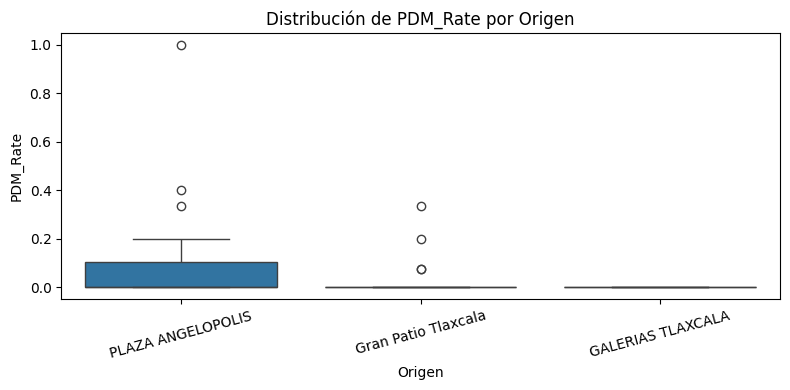

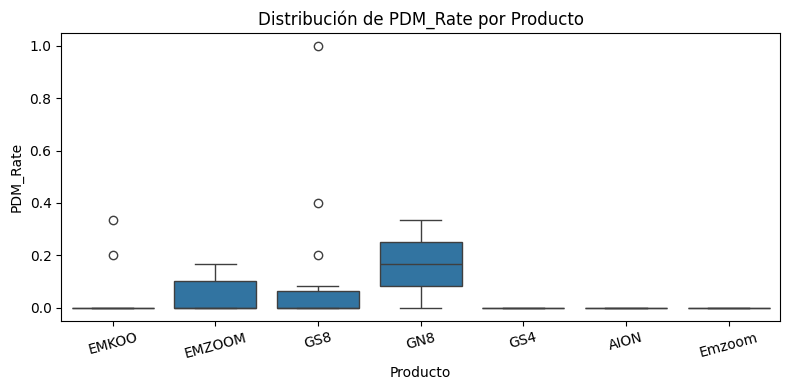

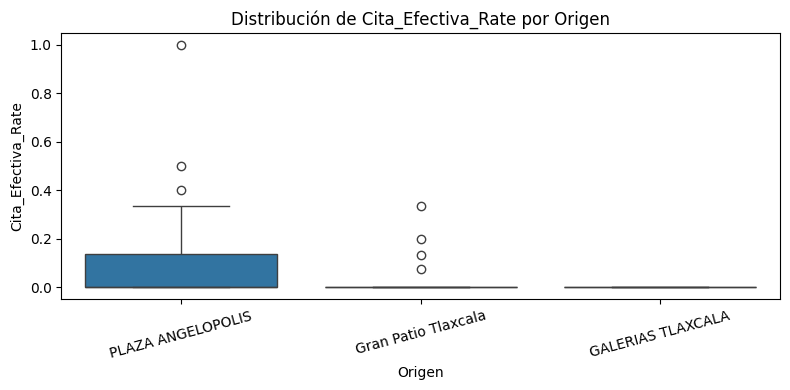

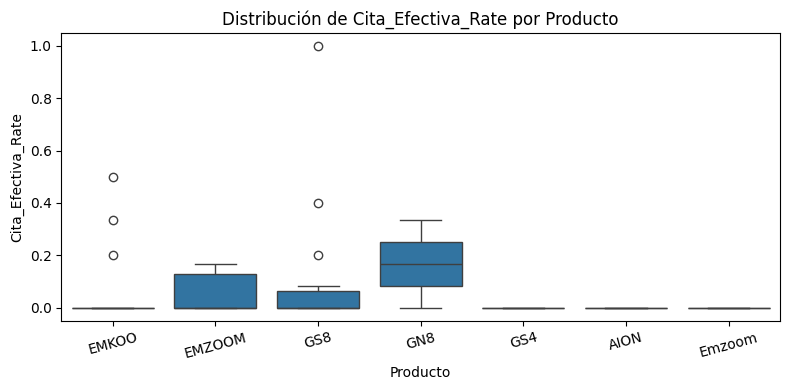

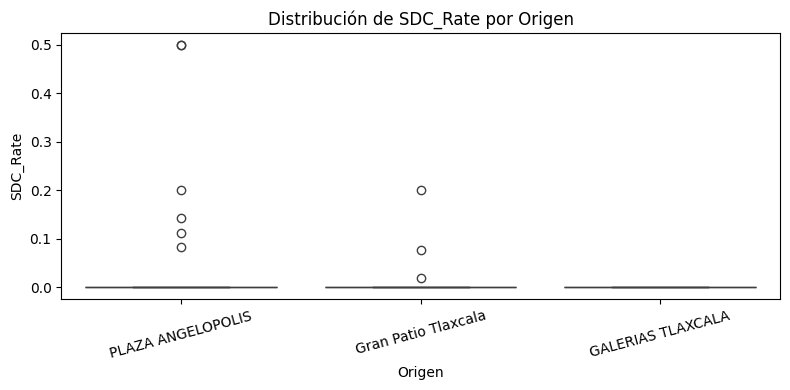

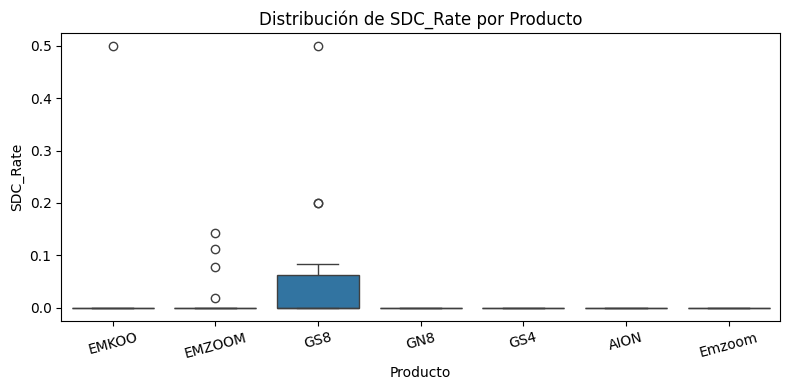

In [21]:
# 6 boxplots
variables_cuantitativas = ['PDM_Rate', 'Cita_Efectiva_Rate', 'SDC_Rate']
variables_cualitativas = ['Origen', 'Producto']

for var_num in variables_cuantitativas:
    for var_cat in variables_cualitativas:
        plt.figure(figsize=(8, 4))
        sns.boxplot(data=df_grouped, x=var_cat, y=var_num)
        plt.title(f'Distribución de {var_num} por {var_cat}')
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()

## 8. GRÁFICOS DE INTERACCIÓN

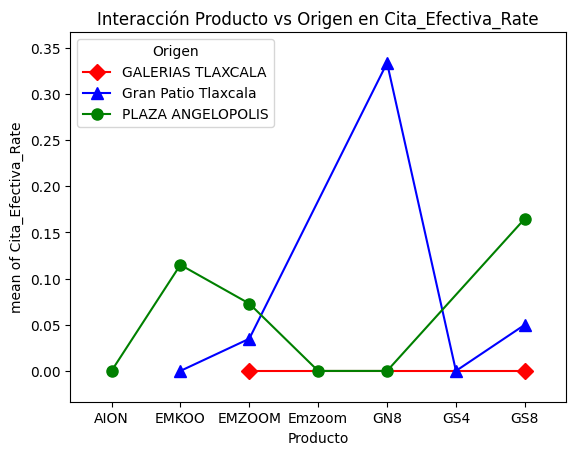

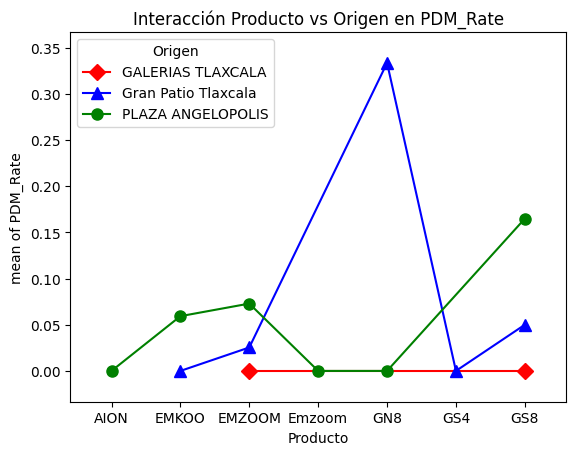

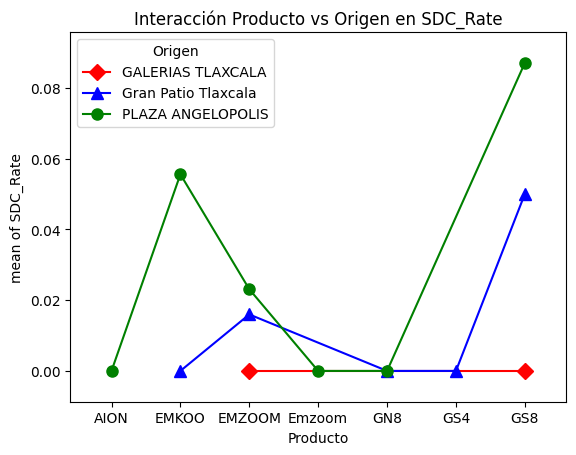

In [22]:
# Gráficos de Interacción (interaction_plot) visto en clase

fig = interaction_plot(df_grouped['Producto'], df_grouped['Origen'], df_grouped['Cita_Efectiva_Rate'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=8)
plt.title('Interacción Producto vs Origen en Cita_Efectiva_Rate')
plt.show()

fig = interaction_plot(df_grouped['Producto'], df_grouped['Origen'], df_grouped['PDM_Rate'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=8)
plt.title('Interacción Producto vs Origen en PDM_Rate')
plt.show()

fig = interaction_plot(df_grouped['Producto'], df_grouped['Origen'], df_grouped['SDC_Rate'],
                       colors=['red', 'blue', 'green'], markers=['D', '^', 'o'], ms=8)
plt.title('Interacción Producto vs Origen en SDC_Rate')
plt.show()